Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Linear accuracy 0.9385964912280702 Linear precision 0.8292682926829268 Linear recall 1.0


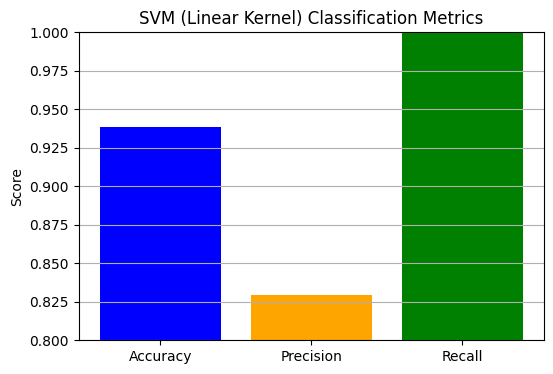

Polynomial accuracy 0.9649122807017544 Polynomial precision 1.0 Polynomial recall 0.8823529411764706


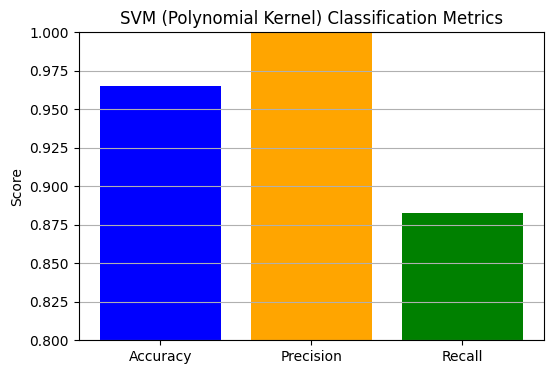

Radial basis function accuracy 0.9736842105263158 Radial basis function precision 0.918918918918919 Radial basis function recall 1.0


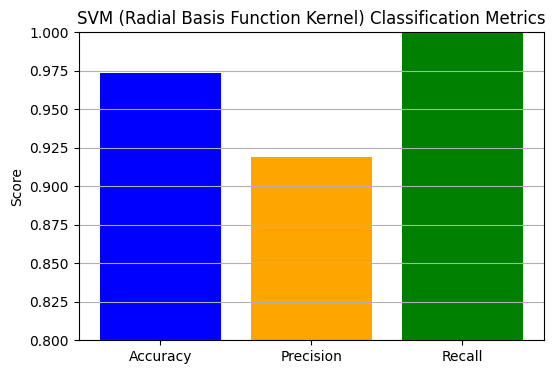

Sigmoid accuracy 0.956140350877193 Sigmoid precision 0.9393939393939394 Sigmoid recall 0.9117647058823529


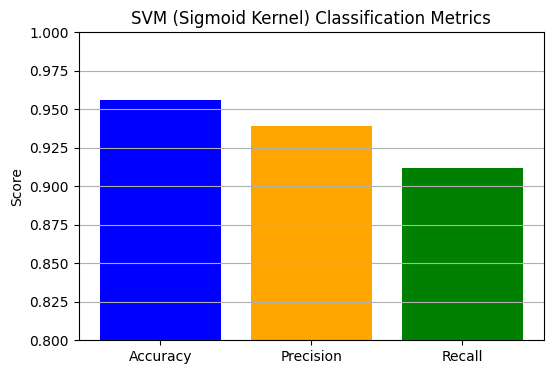

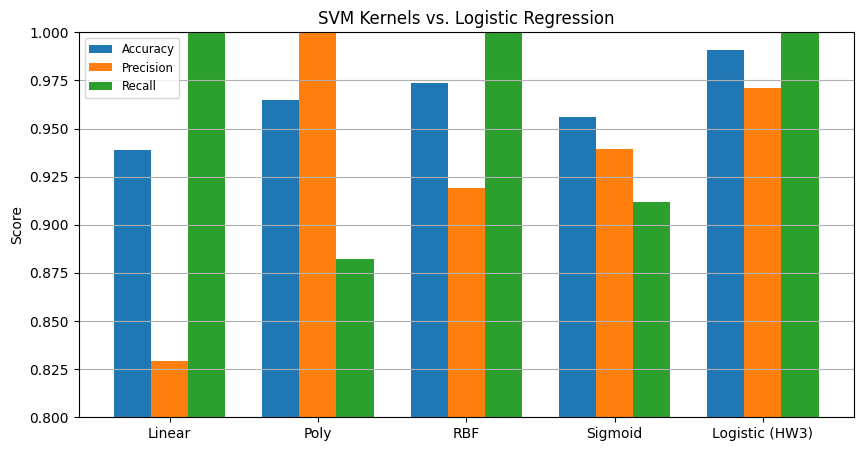

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Machine Learning/Cancer.csv'
Cancer = pd.DataFrame(pd.read_csv(file_path))

def binary_map(x):
  return x.map({'M': 1, 'B': 0})

Cancer[['diagnosis']] = Cancer[['diagnosis']].apply(binary_map)

X = Cancer.iloc[:, 2:32].values
Y = Cancer.iloc[:, 1].values

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size = 0.8,
                                                    test_size = 0.2, random_state = 4)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

from sklearn import svm

linear_classifier = svm.SVC(kernel='linear')
linear_classifier.fit(X_train, Y_train)
Y_pred_linear = linear_classifier.predict(X_test)

poly_classifier = svm.SVC(kernel='poly')
poly_classifier.fit(X_train, Y_train)
Y_pred_poly = poly_classifier.predict(X_test)

rbf_classifier = svm.SVC(kernel='rbf')
rbf_classifier.fit(X_train, Y_train)
Y_pred_rbf = rbf_classifier.predict(X_test)

sigmoid_classifier = svm.SVC(kernel='sigmoid')
sigmoid_classifier.fit(X_train, Y_train)
Y_pred_sigmoid = sigmoid_classifier.predict(X_test)

from sklearn import metrics

linear_acc  = metrics.accuracy_score(Y_test, Y_pred_linear)
linear_prec = metrics.precision_score(Y_test, Y_pred_linear)
linear_rec  = metrics.recall_score(Y_test, Y_pred_linear)
print("Linear accuracy", linear_acc, "Linear precision", linear_prec,
      "Linear recall", linear_rec)

plt.figure(figsize=(6, 4))
plt.bar(['Accuracy', 'Precision', 'Recall'], [linear_acc, linear_prec, linear_rec], color=['blue', 'orange', 'green'])
plt.ylim(0.8, 1.0)
plt.ylabel('Score')
plt.title('SVM (Linear Kernel) Classification Metrics')
plt.grid(axis='y')
plt.show()

poly_acc  = metrics.accuracy_score(Y_test, Y_pred_poly)
poly_prec = metrics.precision_score(Y_test, Y_pred_poly)
poly_rec  = metrics.recall_score(Y_test, Y_pred_poly)
print("Polynomial accuracy", poly_acc, "Polynomial precision", poly_prec, "Polynomial recall", poly_rec)

plt.figure(figsize=(6, 4))
plt.bar(['Accuracy', 'Precision', 'Recall'], [poly_acc, poly_prec, poly_rec], color=['blue', 'orange', 'green'])
plt.ylim(0.8, 1.0)
plt.ylabel('Score')
plt.title('SVM (Polynomial Kernel) Classification Metrics')
plt.grid(axis='y')
plt.show()

rbf_acc  = metrics.accuracy_score(Y_test, Y_pred_rbf)
rbf_prec = metrics.precision_score(Y_test, Y_pred_rbf)
rbf_rec  = metrics.recall_score(Y_test, Y_pred_rbf)
print("Radial basis function accuracy", rbf_acc, "Radial basis function precision", rbf_prec, "Radial basis function recall", rbf_rec)

plt.figure(figsize=(6, 4))
plt.bar(['Accuracy', 'Precision', 'Recall'], [rbf_acc, rbf_prec, rbf_rec], color=['blue', 'orange', 'green'])
plt.ylim(0.8, 1.0)
plt.ylabel('Score')
plt.title('SVM (Radial Basis Function Kernel) Classification Metrics')
plt.grid(axis='y')
plt.show()

sigmoid_acc  = metrics.accuracy_score(Y_test, Y_pred_sigmoid)
sigmoid_prec = metrics.precision_score(Y_test, Y_pred_sigmoid)
sigmoid_rec  = metrics.recall_score(Y_test, Y_pred_sigmoid)
print("Sigmoid accuracy", sigmoid_acc, "Sigmoid precision", sigmoid_prec, "Sigmoid recall", sigmoid_rec)

plt.figure(figsize=(6, 4))
plt.bar(['Accuracy', 'Precision', 'Recall'], [sigmoid_acc, sigmoid_prec, sigmoid_rec], color=['blue', 'orange', 'green'])
plt.ylim(0.8, 1.0)
plt.ylabel('Score')
plt.title('SVM (Sigmoid Kernel) Classification Metrics')
plt.grid(axis='y')
plt.show()

labels = ['Linear', 'Poly', 'RBF', 'Sigmoid', 'Logistic (HW3)']
acc  = [linear_acc, poly_acc, rbf_acc, sigmoid_acc, 0.991]
prec = [linear_prec, poly_prec, rbf_prec, sigmoid_prec, 0.971]
rec  = [linear_rec, poly_rec, rbf_rec, sigmoid_rec, 1.0]

x = np.arange(len(labels))
w = 0.25
plt.figure(figsize=(10, 5))
plt.bar(x - w, acc,  w, label='Accuracy')
plt.bar(x,     prec, w, label='Precision')
plt.bar(x + w, rec,  w, label='Recall')
plt.xticks(x, labels)
plt.ylim(0.8, 1.0)
plt.ylabel('Score')
plt.title('SVM Kernels vs. Logistic Regression')
plt.legend(fontsize='small')
plt.grid(axis='y')
plt.show()
